# Librerias

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm
%matplotlib inline

# Load Data

In [ ]:
data = load_iris()
data.keys()

dict_keys(['data', 'target', 'target_names', 'DESCR', 'feature_names', 'filename'])

In [ ]:
print(data['DESCR'])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

    :Number of Instances: 150 (50 in each of three classes)
    :Number of Attributes: 4 numeric, predictive attributes and the class
    :Attribute Information:
        - sepal length in cm
        - sepal width in cm
        - petal length in cm
        - petal width in cm
        - class:
                - Iris-Setosa
                - Iris-Versicolour
                - Iris-Virginica
                
    :Summary Statistics:

    ============== ==== ==== ======= ===== ====================
                    Min  Max   Mean    SD   Class Correlation
    ============== ==== ==== ======= ===== ====================
    sepal length:   4.3  7.9   5.84   0.83    0.7826
    sepal width:    2.0  4.4   3.05   0.43   -0.4194
    petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
    petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
    ============== ==== ==== ======= ===== ===========

In [ ]:
pd.DataFrame(data['data'], columns=data['feature_names']).head(3)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


In [ ]:
x = data['data']

x.shape

(150, 4)

In [ ]:
x[:3]

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2]])

In [ ]:
type(x)

numpy.ndarray

In [ ]:
y = data['target']

y.shape

(150,)

In [ ]:
y[:5]

array([0, 0, 0, 0, 0])

In [ ]:
set(y)

{0, 1, 2}

In [ ]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [ ]:
# Cambiamos la representacion de y a one-hot
y = np.eye(3)[y]

y.shape

(150, 3)

In [ ]:
y

array([[1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0

In [ ]:
# Train validation split
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.shape, x_val.shape, y_train.shape, y_val.shape

((120, 4), (30, 4), (120, 3), (30, 3))

In [ ]:
data['target_names']

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [ ]:
for i,e in enumerate(data['target_names']):
  print(i,e)

0 setosa
1 versicolor
2 virginica


In [ ]:
# Armamos un diccionario para el target
idx2class = {i:e for i,e in enumerate(data['target_names'])}
idx2class

{0: 'setosa', 1: 'versicolor', 2: 'virginica'}

# PyTorch

In [ ]:
# Params
bs = 32 # Batch size
epochs = 25
lr = 0.1
nb = math.ceil(len(x_train) / bs)  # Número de batches por epoch

In [ ]:
nb

4

In [ ]:
import torch

# Modelo
class NeuralNet(torch.nn.Module):
  def __init__(self):
    super(NeuralNet, self).__init__()

    self.output = torch.nn.Linear(4, 3)

  def forward(self, x):
    x = self.output(x)

    return x

model = NeuralNet()

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

model.eval()

NeuralNet(
  (output): Linear(in_features=4, out_features=3, bias=True)
)

In [ ]:
train_losses = []
val_losses = []

for epoch in tqdm(range(epochs)):
  for i in range(nb):
    batch_x = torch.tensor(x_train[i*bs:(i+1)*bs], dtype=torch.float32)
    batch_y = torch.tensor(y_train[i*bs:(i+1)*bs], dtype=torch.float32)

    # PyTorch acumula gradientes, por eso necesitamos eliminarlas antes de cada instancia
    model.zero_grad()

    predictions = model(batch_x)

    batch_y = batch_y.max(dim=1).indices

    loss = loss_function(predictions, batch_y)
    loss.backward()

    optimizer.step()

  with torch.no_grad():
    all_x_train = torch.tensor(x_train, dtype=torch.float32)
    all_y_train = torch.tensor(y_train, dtype=torch.float32)

    train_loss = loss_function(model(all_x_train), all_y_train.max(dim=1).indices)
    train_losses.append(train_loss)

    all_x_val = torch.tensor(x_val, dtype=torch.float32)
    all_y_val = torch.tensor(y_val, dtype=torch.float32)

    val_loss = loss_function(model(all_x_val), all_y_val.max(dim=1).indices)
    val_losses.append(val_loss)

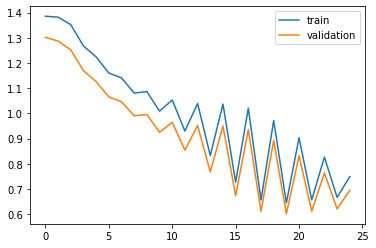

In [ ]:
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='validation')
plt.legend()

## Resultados

In [ ]:
with torch.no_grad():
  all_x_val = torch.tensor(x_val, dtype=torch.float32)
  all_y_val = torch.tensor(y_val, dtype=torch.float32)

  pred, pred_loss = model(all_x_val), loss_function(model(all_x_val), all_y_val.max(dim=1).indices)

In [ ]:
pred_loss.numpy()

array(0.6949283, dtype=float32)

In [ ]:
y_val[0], torch.nn.functional.softmax(pred[0], dim=0).numpy()

(array([0., 1., 0.]),
 array([0.02338379, 0.08881624, 0.8878    ], dtype=float32))

In [ ]:
# Para obtener las predicciones finales vamos a usar np.argmax,
# que devuelve el indice con el mayor valor
np.argmax(y_val[0]), np.argmax(torch.nn.functional.softmax(pred[0], dim=0).numpy())

(1, 2)

In [ ]:
# Obtenemos todos los labels
real_labels = np.argmax(y_val, axis=1)
pred_labels = np.argmax(torch.nn.functional.softmax(pred, dim=1).numpy(), axis=1)

In [ ]:
real_labels[:], pred_labels[:]

(array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
        0, 2, 2, 2, 2, 2, 0, 0]),
 array([2, 0, 2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 2, 2, 2, 2, 2, 0, 2,
        0, 2, 2, 2, 2, 2, 0, 0]))

In [ ]:
# Vamos a usar una metrica de accuracy para comparar los resultados
pred_acc = (real_labels == pred_labels).mean()

pred_acc

0.7

In [ ]:
print(f'Loss = {pred_loss:.2f}\nAccuracy = {pred_acc:.2f}')

Loss = 0.69
Accuracy = 0.70


# Observamos nuestro modelo

In [ ]:
import plotly.express as px

def plot_logistic_regression_for_training(title=''):
  dataframe_for_x = pd.DataFrame(x_train, columns=["sepal length (cm)",	"sepal width (cm)",	"petal length (cm)",	"petal width (cm)"]).reset_index(drop=True)

  with torch.no_grad():
    all_x_train = torch.tensor(x_train, dtype=torch.float32)

    dataframe_for_y = pd.DataFrame(np.argmax(torch.nn.functional.softmax(model(all_x_train), dim=1).numpy(), axis=1), columns=["target"]).reset_index(drop=True)

  dataframe = pd.concat([dataframe_for_x, dataframe_for_y], axis=1)

  figure = px.scatter_3d(dataframe, x="sepal length (cm)", y="petal length (cm)", z="petal width (cm)", color="target", width=1000, height=1000, title=title)
  figure.show()

def plot_logistic_regression_for_testing(title=''):
  dataframe_for_x = pd.DataFrame(x_val, columns=["sepal length (cm)",	"sepal width (cm)",	"petal length (cm)",	"petal width (cm)"]).reset_index(drop=True)

  with torch.no_grad():
    all_x_val = torch.tensor(x_val, dtype=torch.float32)

    dataframe_for_y = pd.DataFrame(np.argmax(torch.nn.functional.softmax(model(all_x_val), dim=1).numpy(), axis=1), columns=["target"]).reset_index(drop=True)

  dataframe = pd.concat([dataframe_for_x, dataframe_for_y], axis=1)

  figure = px.scatter_3d(dataframe, x="sepal length (cm)", y="petal length (cm)", z="petal width (cm)", color="target", width=1000, height=1000, title=title)
  figure.show()

In [ ]:
plot_logistic_regression_for_training("Regresión Logística con los datos de entrenamiento")

In [ ]:
plot_logistic_regression_for_testing("Regresión Logística con los datos de prueba")

# Aumentando la cantidad de parámetros

In [ ]:
i = np.random.choice(len(x_train))
i = 0
eg_x = x_train[i][:,None]
eg_y = y_train[i]
eg_w = np.random.normal(size=4*3).reshape((3,4))
eg_b = np.random.normal(size=3)

Si vemos nuevamente el ejemplo, la capacidad del modelo depende en parte de la cantidad de parametros que puede aprender:

In [ ]:
eg_x.shape, eg_w.shape, eg_b.shape

((4, 1), (3, 4), (3,))

En este caso la matriz **eg_w** tiene 12 parámetros y **eg_b** tiene 3 parámetros. Por lo que nuestro modelo tiene un **total de 15 parámetros**.

**¿Cómo incrementamos el número de parámetros?**

Tenemos: `w(3x4) @ x(4x1) = (3x1)` (3x4 = 12 parámetros)

Agregamos una matriz intermedia: `w1(10x4) @ x(4x1) = (10x1) -->  w2(3x10) @ (10x1) = (3x1)` (10x4 + 3x10 = 70 parámetros)

**Agregando una matriz intermedia incrementamos los parámetros de 12 a 70.**

In [ ]:
i = np.random.choice(len(x_train))
i = 0
eg_x = x_train[i][:,None]
eg_y = y_train[i]
eg_w1 = np.random.normal(size=10*4).reshape((10,4))
eg_b1 = np.random.normal(size=10).reshape((10,1))
eg_w2 = np.random.normal(size=3*10).reshape((3,10))
eg_b2 = np.random.normal(size=3).reshape((3,1))

In [ ]:
temp = ((eg_w1 @ eg_x) + eg_b1)
temp.shape

(10, 1)

In [ ]:
y_ = ((eg_w2 @ temp) + eg_b2).ravel()
y_.shape

(3,)

**Pero hay un problema con esta formulación:** un conjunto de operaciones lineales (multiplicaciones y sumas), se pueden reducir a una sola multiplicacion y suma:

$ y_1 = 2x + 10 $

$ y_2 = softmax(3y_1 - 5) = softmax(((2x + 10) * 3) - 5) = softmax(6x + 25) $

<br>

**Solucion: Funciones de activación**

La idea de las funciones de activación es agregar funciones no lineales entre capa y capa (capa = multiplicacion+suma).

$ y_1 = \sigma(2x + 10) $

$ y_2 = softmax(3y_1 - 5) $

\* *La funcion softmax se considera una funcion de activación.*

In [ ]:
# Params
bs = 32 # Batch size
epochs = 150
lr = 0.01
nb = math.ceil(len(x_train) / bs) # Numero de batches por epoch

In [ ]:
nb

4

In [ ]:
import torch

# Modelo
class NeuralNet(torch.nn.Module):
  def __init__(self):
    super(NeuralNet, self).__init__()

    self.intermediate = torch.nn.Linear(4, 10)

    self.intermediate_activation = torch.nn.ReLU()

    self.output = torch.nn.Linear(10, 3)

  def forward(self, x):
    x = self.intermediate(x)
    x = self.intermediate_activation(x)
    x = self.output(x)

    return x

model = NeuralNet()

loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

model.eval()

NeuralNet(
  (intermediate): Linear(in_features=4, out_features=10, bias=True)
  (intermediate_activation): ReLU()
  (output): Linear(in_features=10, out_features=3, bias=True)
)

In [ ]:
train_losses = []
val_losses = []

for epoch in tqdm(range(epochs)):
  for i in range(nb):
    batch_x = torch.tensor(x_train[i*bs:(i+1)*bs], dtype=torch.float32)
    batch_y = torch.tensor(y_train[i*bs:(i+1)*bs], dtype=torch.float32)

    # PyTorch acumula gradientes, por eso necesitamos eliminarlas antes de cada instancia
    model.zero_grad()

    predictions = model(batch_x)

    batch_y = batch_y.max(dim=1).indices

    loss = loss_function(predictions, batch_y)
    loss.backward()

    optimizer.step()

  with torch.no_grad():
    all_x_train = torch.tensor(x_train, dtype=torch.float32)
    all_y_train = torch.tensor(y_train, dtype=torch.float32)

    train_loss = loss_function(model(all_x_train), all_y_train.max(dim=1).indices)
    train_losses.append(train_loss)

    all_x_val = torch.tensor(x_val, dtype=torch.float32)
    all_y_val = torch.tensor(y_val, dtype=torch.float32)

    val_loss = loss_function(model(all_x_val), all_y_val.max(dim=1).indices)
    val_losses.append(val_loss)

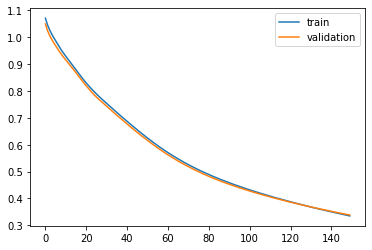

In [ ]:
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='validation')
plt.legend()

In [ ]:
with torch.no_grad():
  all_x_val = torch.tensor(x_val, dtype=torch.float32)
  all_y_val = torch.tensor(y_val, dtype=torch.float32)

  pred, pred_loss = model(all_x_val), loss_function(model(all_x_val), all_y_val.max(dim=1).indices)

In [ ]:
pred_loss.numpy()

array(0.3384199, dtype=float32)

In [ ]:
real_labels = np.argmax(y_val, axis=1)
pred_labels = np.argmax(torch.nn.functional.softmax(pred, dim=1).numpy(), axis=1)

In [ ]:
pred_acc = (real_labels == pred_labels).mean()

pred_acc

0.9333333333333333

In [ ]:
print(f'Loss = {pred_loss:.2f}\nAccuracy = {pred_acc:.2f}')

Loss = 0.34
Accuracy = 0.93


# Observamos nuestro modelo

In [ ]:
import plotly.express as px

def plot_logistic_regression_for_training(title=''):
  dataframe_for_x = pd.DataFrame(x_train, columns=["sepal length (cm)",	"sepal width (cm)",	"petal length (cm)",	"petal width (cm)"]).reset_index(drop=True)

  with torch.no_grad():
    all_x_train = torch.tensor(x_train, dtype=torch.float32)

    dataframe_for_y = pd.DataFrame(np.argmax(torch.nn.functional.softmax(model(all_x_train), dim=1).numpy(), axis=1), columns=["target"]).reset_index(drop=True)

  dataframe = pd.concat([dataframe_for_x, dataframe_for_y], axis=1)

  figure = px.scatter_3d(dataframe, x="sepal length (cm)", y="petal length (cm)", z="petal width (cm)", color="target", width=1000, height=1000, title=title)
  figure.show()

def plot_logistic_regression_for_testing(title=''):
  dataframe_for_x = pd.DataFrame(x_val, columns=["sepal length (cm)",	"sepal width (cm)",	"petal length (cm)",	"petal width (cm)"]).reset_index(drop=True)

  with torch.no_grad():
    all_x_val = torch.tensor(x_val, dtype=torch.float32)

    dataframe_for_y = pd.DataFrame(np.argmax(torch.nn.functional.softmax(model(all_x_val), dim=1).numpy(), axis=1), columns=["target"]).reset_index(drop=True)

  dataframe = pd.concat([dataframe_for_x, dataframe_for_y], axis=1)

  figure = px.scatter_3d(dataframe, x="sepal length (cm)", y="petal length (cm)", z="petal width (cm)", color="target", width=1000, height=1000, title=title)
  figure.show()

In [ ]:
plot_logistic_regression_for_training("Regresión Logística con los datos de entrenamiento")

In [ ]:
plot_logistic_regression_for_testing("Regresión Logística con los datos de prueba")